# A Brief Introduction to pyPalace
[pyPalace](https://pypalace.readthedocs.io/en/latest/) is an open-source Python toolkit for simulating and analyzing superconducting quantum devices with AWS Palace.


This notebook follows [Example 01 (eigenmode + EPR)](https://github.com/FirasAbouzahr/pyPalace/tree/main/Examples/example_01_eigenmode_EPR) in the pyPalace repository.

### What pyPalace helps you do:
* **Build** Palace configuration files from Python (Config + builder helpers)
* **Run** electrostatic, magnetostatic, eigenmode, and driven (time- or frequency-domain) simulations locally (mpirun) or on HPC (Slurm)
* **Extract standard outputs** (capacitance matrices, eigenfrequencies, S-parameters, fields)
* **Analyze superconducting circuits** with quantum-oriented utilities such as Lumped Oscillator Modeling (LOM) and Energy Participation Ratio (EPR)


# Eigenmode simulations for superconducting circuits

## What are eigenmode simulations?

Eigenmode simulations solve the source-free electromagnetic wave equation. For nonmagnetic media ($\mu_r = 1$, as assumed throughout for these dielectrics and superconductors) this reads

$$\nabla \times (\nabla \times \mathbf{E}) - \epsilon_r\left(\frac{\omega}{c}\right)^2\mathbf{E} = 0,$$

which is the source-free limit of the general curl–curl form $\nabla \times \mu_r^{-1}\nabla \times \mathbf{E} = k_0^2\,\epsilon_r\,\mathbf{E}$ ($k_0 = \omega/c$ is the free-space wavenumber); see [Elkin et al., arXiv:2511.20774 (2025)](https://arxiv.org/abs/2511.20774), Eq. (33).


Palace is an open-source Finite Element Method (FEM) solver that performs complex physics simulations on digitized objects. To do this, a process called meshing first divides the complex geometric model into a network of small, simple shapes called elements. Palace then solves the physics equations piece by piece across this network to calculate how the whole structure will behave. In this light, more accurately, Palace solves the *discretized* version of the source-free electromagnetic wave equation (see the [Palace documentation](https://awslabs.github.io/palace/stable/reference/#Eigenmode-calculations)). In current practice, FEM is the standard CEM method used for cQED device modeling ([Elkin et al., arXiv:2511.20774 (2025)](https://arxiv.org/abs/2511.20774), Sec. III F).


## Why eigenmode simulations?
Eigenmode simulations determine the natural resonant frequencies and electromagnetic field distributions supported by a structure. In other words, they identify the standing-wave modes that can exist without an external drive.

For superconducting circuits, eigenmode simulations are used to extract resonant frequencies, mode shapes, and quality factors. The resulting electric and magnetic field distributions can then be used in Energy Participation Ratio (EPR) analysis, which quantifies how electromagnetic energy is distributed throughout the device. These participation ratios are subsequently used to extract Hamiltonian parameters such as qubit anharmonicity ($\alpha$) and the resonator dispersive shift ($\chi$).

# Eigenmode simulation and EPR analysis of transmon-resonator system

## Coupled transmon-resonator device


In [4]:

import os
os.environ.setdefault("QISKIT_METAL_HEADLESS", "1")
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")
os.environ.setdefault("MPLBACKEND", "Agg")

import qiskit_metal as metal
from qiskit_metal import designs, draw
from qiskit_metal import Dict, Headings
from qiskit_metal import MetalGUI

from qiskit_metal import designs, MetalGUI, Dict, view
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.terminations.launchpad_wb_driven import LaunchpadWirebondDriven
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander

# from SQDMetal.Comps.Xmon import Xmon
# from SQDMetal.Comps.Junctions import JunctionDolanPinStretch
# from SQDMetal.Comps.Capacitors import CapacitorProngPin
# from SQDMetal.Utilities.Materials import MaterialInterface

/home/aashay2/metal-flow/quantum-metal/src/qiskit_metal/qgeometries/qgeometries_handler.py:537: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.tables[kind] = pd.concat(


components: ['Q1', 'LP_L', 'LP_R', 'cplr', 'feed_left', 'feed_right', 'readout_Q1']


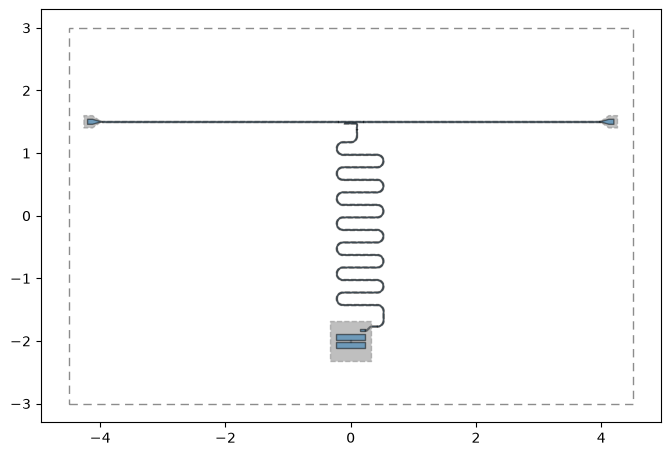

In [12]:
design = designs.DesignPlanar()
design.overwrite_enabled = True
design.chips.main.size['size_x'] = '9mm'
design.chips.main.size['size_y'] = '6mm'

um = 1e-3

# --- transmon ---------------------------------------------------------------------
q1 = TransmonPocket(design, 'Q1', options=Dict(
    pos_x='0mm', pos_y='-2.0mm',
    pad_width='455um', pad_height='90um', pad_gap='30um',
    pocket_width='650um', pocket_height='650um',
    connection_pads=Dict(
        readout=Dict(loc_W=+1, loc_H=+1, pad_width='80um', pad_gap='50um'),
    ),
))

# --- feedline: launchpad -- coupled-line tee -- launchpad ----------------------------
lp_l = LaunchpadWirebondDriven(design, 'LP_L', options=Dict(
    pos_x='-4.0mm', pos_y='1.5mm', orientation='0'))
lp_r = LaunchpadWirebondDriven(design, 'LP_R', options=Dict(
    pos_x='4.0mm', pos_y='1.5mm', orientation='180'))

# Tee: 'prime' line is the feedline, 'second' arm couples to the resonator.
# If the second arm points away from the qubit in the plot, flip it with mirror=True or orientation.
cplr = CoupledLineTee(design, 'cplr', options=Dict(
    pos_x='0mm', pos_y='1.5mm',
    coupling_length='200um', coupling_space='5um', down_length='100um'))

feed_left = RouteStraight(design, 'feed_left', options=Dict(pin_inputs=Dict(
    start_pin=Dict(component='LP_L', pin='tie'),
    end_pin=Dict(component='cplr', pin='prime_start'))))
feed_right = RouteStraight(design, 'feed_right', options=Dict(pin_inputs=Dict(
    start_pin=Dict(component='cplr', pin='prime_end'),
    end_pin=Dict(component='LP_R', pin='tie'))))

# --- readout resonator ----------------------------------------------------------------
res = RouteMeander(design, 'readout_Q1', options=Dict(
    total_length='12mm',
    fillet='99um',
    lead=Dict(start_straight='200um', end_straight='100um'),
    meander=Dict(spacing='200um', asymmetry='50um'),
    pin_inputs=Dict(
        start_pin=Dict(component='cplr', pin='second_end'),
        end_pin=Dict(component='Q1', pin='readout')),
))

design.rebuild()

print('components:', list(design.components.keys()))
view(design)


     
# ## create a rectangle that we will use as our JJ lumped port --> more on this below
# JJ_y2 = float(xmon.options["pos_y"]) - float(xmon.options["cross_height"][:-2])*um/2 ## do some simple algebra to place it appropriately on the xmon
# JJ_y1 = JJ_y2 - float(xmon.options["gap_down"][:-2])*um
# JJ_y = (JJ_y1 + JJ_y2)/2
# JJ_length = abs(JJ_y2-JJ_y1)
# JJ_width = 5.4*um
# JJ_geometry = draw.rectangle(JJ_width,JJ_length,0,JJ_y)
# design.qgeometry.add_qgeometry("poly",xmon.id,{"josephson_junction": JJ_geometry},layer=1,subtract=False)

# res_options = res1.options
# LP1_options = LP1.options
# port1_x = (float(LP1_options["pos_x"][:-2]) 
#          - (float(LP1_options["pad_width"][:-2]) 
#          + float(LP1_options["taper_height"][:-2])) * um 
#          - float(LP1_options["pad_gap"][:-2])/2 * um)
# port1_y = float(LP1_options["pos_y"][:-2])
# port1_width = float(LP1_options["pad_gap"][:-2])*um
# port1_length = float(LP1_options["pad_height"][:-2])*um
# feedline_port1 = draw.rectangle(port1_width,port1_length, port1_x, port1_y)
# design.qgeometry.add_qgeometry("poly",LP1.id,{"feedline_port1": feedline_port1},layer=1,subtract=False)

# LP2_options = LP2.options
# port2_x = (float(LP2_options["pos_x"][:-2]) 
#          + (float(LP2_options["pad_width"][:-2]) 
#          + float(LP2_options["taper_height"][:-2])) * um 
#          + float(LP2_options["pad_gap"][:-2])/2 * um)
# port2_y = float(LP2_options["pos_y"][:-2])
# port2_width = float(LP2_options["pad_gap"][:-2])*um
# port2_length = float(LP2_options["pad_height"][:-2])*um
# feedline_port2 = draw.rectangle(port2_width,port2_length, port2_x, port2_y)
# design.qgeometry.add_qgeometry("poly",LP2.id,{"feedline_port2": feedline_port2},layer=1,subtract=False)

# # rebuild the GUI
# gui.refresh()
# gui.autoscale()

### <u>Modeling junctions</u>

There are two critical points regarding modeling junctions in electromagnetic simulations:
1. Junctions are nanometer-scale components, this makes it very hard to mesh them, especially because other meshed components are on the scale of tens to hundreds of microns. Instead we replace the junction geometry with a simple rectangle and define it as a lumped port.
2. Junctions are modeled as lumped ports with a *linear* inductance. FEM simulations are inherently classical and most (or all), solvers do not have the ability to assign a port a non-linear inductance.

# Meshing

Before a simulation can be solved, the geometry must be discretized into a collection of small elements called a **mesh**. Rather than solving Maxwell's equations exactly on a continuous geometry, finite element tools (like Palace) solve them on this discretized representation. In general, a finer mesh provides a more accurate representation of the true geometry, but increases computational cost.

### <u>Some "Rules of thumb" for meshing</u>

* The initial mesh on resonant structures should have an element size no larger than approximately $\lambda/4$, where $\lambda$ is the wavelength at the frequency of interest. <!-- *I've heard plenty of variations of this rule, $\lambda/4$, $\lambda/10$, $\lambda/20$...* For cQED devices, however, the wavelength is usually not what limits the mesh: the relevant features (gaps, junction leads, thin films) are far smaller than the wavelength: the structures are *electrically small*. So, that part of the mesh must be made smaller to accommodate these small features. Since some features are much smaller than others, we end up with a mix of tiny and large elements (making the mesh everywhere tiny would be too slow to solve). This spread of element sizes makes the problem *multiscale*, which ill-conditions the matrix: big and small elements give entries of very different sizes, and since the computer only keeps so many digits, the small ones can get rounded away when mixed with the big ones, leaving the solver without the information it needs to converge ([Elkin et al., arXiv:2511.20774 (2025)](https://arxiv.org/abs/2511.20774), Sec. V C). -->
* Finer meshes generally produce more accurate simulations because they better approximate the true device geometry and electromagnetic fields.
* Mesh refinement should be focused in regions where fields vary rapidly or where geometric details are important (e.g., coupling gaps, junction regions, or generally important circuit components).
* Coarser meshes can often be used in regions that have little impact on the quantities of interest, reducing simulation time and memory usage.

# Mesh Quantum Metal design with pyPalace (Gmsh backend)

In Palace, mesh attributes provide the labels used to specify entries in `config["Domains"]` (volume regions or related postprocessing) and `config["Boundaries"]` (surface regions where we apply boundary conditions or related postprocessing).

pyPalace leaves it up to the user to define which Quantum Metal surfaces we want to give mesh attributes for full flexibility. Volumes (substrate & air box), the far field, and the ground plane are automatically assigned mesh attributes. Let's take a look at our Quantum Metal design surfaces table:

In [3]:
from pypalace import mesh

In [4]:
surface_table = mesh.get_quantum_metal_surfaces(design)
surface_table

,component_id,component_name,name,subtract
0,1,xmon,cross,False
1,1,xmon,gap,True
2,2,claw,pad,False
3,2,claw,padGap,True
4,3,LP1,launch_pad,False
5,3,LP1,pocket,True
6,4,LP2,launch_pad,False
7,4,LP2,pocket,True
8,6,otg1,open_to_ground,True
9,1,xmon,josephson_junction,False


Polygons with `subtract == True` are the designs' metal (superconducting thin-film) components, while polygons with `subtract == False` are etched regions. We will want to give all metal components some boundary condition, so we need to give all of these mesh attributes. 

For interface dielectric losses (boundaries postprocessing), we would also want to assign etched regions mesh attributes as well. For this example, we will skip this. 

In [5]:
# each dictionary component has entry component ID, name, mesh attribute ID we want to assign it
attributes = {}

# this loop is simply assigning every metal component in our design a mesh attribute
mesh_num = 1
for row in range(len(surface_table)):
    this_component = surface_table.iloc[row]
    if this_component["subtract"] == False:
        name = this_component["name"]
        comp_id = this_component["component_id"]
        attributes[(comp_id,name)] = mesh_num
        mesh_num += 1 # cannot repeat mesh IDs or Palace will fail


# we will also give attributes to the dielectric gaps of/near to show an example of interface dielectric loss analysis
attributes[(1,'gap')] = mesh_num+1
attributes[(2,'padGap')] = mesh_num+2

attributes # each dictionary entry follows: (<component ID number>, <surface name>): <mesh attribute number> 

{(1, 'cross'): 1,
 (2, 'pad'): 2,
 (3, 'launch_pad'): 3,
 (4, 'launch_pad'): 4,
 (1, 'josephson_junction'): 5,
 (3, 'feedline_port1'): 6,
 (4, 'feedline_port2'): 7,
 (5, 'trace'): 8,
 (7, 'trace'): 9,
 (1, 'gap'): 11,
 (2, 'padGap'): 12}

## Mesh the design

now that we have defined a dictionary for the Quantum Metal surfaces we want to give boundary conditions, we can actually mesh our design:

> For time constraints of this demo, we use a coarse mesh and will not implement AMR. In practice, one should either start with a fine mesh (if you have strong previous knowledge of the field distributions) or apply AMR. 

In [6]:
mesh_dir = "mesh/"
meshfile = "eigenmode_epr.msh"
path_to_mesh = mesh_dir + meshfile

## mesh the design --> returns pandas.dataframe of labeled mesh attributes ##
## look at readthedocs, mesh_Quantum_Metal_design has a lot of flexibility to control surface mesh size, volume mesh size, substrate size, etc ## 
attributes_table = mesh.mesh_Quantum_Metal_design(design,
                                                  output_mesh=path_to_mesh,
                                                  Attributes=attributes,
                                                  );

Info    : Meshing 1D...                                                                                                                   
Info    : [  0%] Meshing curve 97 (Line)
Info    : [ 10%] Meshing curve 98 (Line)
Info    : [ 10%] Meshing curve 99 (Line)
Info    : [ 10%] Meshing curve 100 (Line)
Info    : [ 10%] Meshing curve 293 (Line)
Info    : [ 10%] Meshing curve 467 (Line)
Info    : [ 10%] Meshing curve 468 (Line)
Info    : [ 10%] Meshing curve 469 (Line)
Info    : [ 10%] Meshing curve 470 (Line)
Info    : [ 10%] Meshing curve 471 (Line)
Info    : [ 10%] Meshing curve 472 (Line)
Info    : [ 10%] Meshing curve 473 (Line)
Info    : [ 10%] Meshing curve 474 (Line)
Info    : [ 10%] Meshing curve 475 (Line)
Info    : [ 10%] Meshing curve 476 (Line)
Info    : [ 10%] Meshing curve 477 (Line)
Info    : [ 10%] Meshing curve 478 (Line)
Info    : [ 10%] Meshing curve 479 (Line)
Info    : [ 10%] Meshing curve 480 (Line)
Info    : [ 10%] Meshing curve 481 (Line)
Info    : [ 10%] Meshing

`pypalace.mesh.mesh_Quantum_Metal_design` returns an ordered dataframe of the mesh components. We will use these to build our Palace configuration file. Notice this function automatically makes a ground plane, an air box, a substrate box, and the far field. 

In [7]:
attributes_table

,Name,ID,Type
0,1__cross,1,Surface
9,1__gap,11,Surface
10,2__padGap,12,Surface
13,substrate,13,Volume
14,air,14,Volume
11,ground_plane,15,Surface
12,far_field,16,Surface
1,2__pad,2,Surface
2,3__launch_pad,3,Surface
3,4__launch_pad,4,Surface


# Build Palace configuration file with pyPalace

pyPalace follows the Palace configuration schema one-to-one. In this sense, the pyPalace configuration building using `pypalace.Config` and `pypalace.builder` follows directly from the [Palace config documentation](https://awslabs.github.io/palace/stable/config/config/).

In [8]:
from pypalace import Config
from pypalace.builder import Model, Domains, Boundaries, Solver  # these match one-to-one with Palace config syntax

In [9]:
''' choose path & name for Palace configuration file we will build below '''
config_dir = "config/"
path_to_config = config_dir + "eigenmode_epr.json"

## Initialize pyPalace Config object:

In [10]:
eigenmode_config = Config(path_to_config)

## Add `config["Problems"]` and `config["Model"]`

In [11]:
eigenmode_config.add_Problem(Type="Eigenmode",
                             Output="eigenmode_output")

# don't use here but this is how we could add adaptive mesh refinement
#AMR = Model.Refinement(Tol = 1e-6,MaxIts = 3)

# define config["Model"] block
eigenmode_config.add_Model(Mesh = path_to_mesh, # point to our meshfile
                    L0 = 1e-6,# mesh units relative to meters
                    #Refinement=AMR
                    ) 

## Add `config["Domains"]`

Used to define properties and postprocessing for meshed volumes.

### <u>The importance of bulk material properties</u>

Superconducting circuits are fabricated on a dielectric substrate (usually silicon or sapphire). To accurately capture the behavior of our devices, we must model the substrate appropriately — assign accurate values for the electric permittivity ($\epsilon$) and bulk loss tangent ($\tan\delta$). The scaling relations below follow standard circuit-QED considerations ([Blais et al., *Rev. Mod. Phys.* **93**, 025005 (2021)](https://doi.org/10.1103/RevModPhys.93.025005)).

<u>substrate permittivity</u>

Increasing the substrate permittivity increases the capacitance of both CPW resonators and transmon qubits. In general,

$$
C \propto \epsilon.
$$

For a CPW resonator:

$$
v_p = \frac{1}{\sqrt{LC}} \rightarrow f_r \propto v_p \propto \frac{1}{\sqrt{\epsilon_{\mathrm{eff}}}}
$$

For a transmon qubit:

$$E_C = \frac{e^2}{2C_\Sigma} \rightarrow f_q \approx \frac{\sqrt{8E_J E_C} - E_C}{h} \propto \frac{1}{\sqrt{\epsilon}}$$

To leading order $f_q$ is set by the $\sqrt{8E_J E_C}$ term, giving $f_q \propto 1/\sqrt{\epsilon}$; the $-E_C/h$ anharmonicity term scales as $1/\epsilon$.

Thus, increasing the substrate permittivity generally lowers both resonator and qubit eigenfrequencies. However, kinetic inductance (an extra inductance, on top of the usual magnetic inductance, that arises in superconducting devices) can also lower the frequency. Since higher inductance means a lower frequency ($f \approx 1/2\pi\sqrt{LC}$), it acts much as permittivity does through the capacitance. As a result, $\epsilon$ cannot be uniquely determined by matching to a measured frequency alone ([Elkin et al., arXiv:2511.20774 (2025)](https://arxiv.org/abs/2511.20774), Sec. VI A).

<u>bulk loss tangent</u>

The bulk loss tangent ($\tan\delta$) quantifies dielectric dissipation in a material. Unlike the permittivity, it has little effect on the mode frequency and instead affects the mode lifetime.

For a resonator:

$$
Q_{\mathrm{dielectric}} \approx \frac{1}{p\,\tan\delta}
\rightarrow
\kappa = \frac{\omega_r}{Q} \propto \tan\delta
$$

where $p$ is the dielectric participation ratio.

Thus, increasing the bulk loss tangent increases dielectric loss, lowers the quality factor, and broadens the resonator linewidth.

It is also important to account for material anisotropy when applicable, particularly for sapphire substrates whose dielectric properties vary with crystallographic direction.

<u>Common substrate parameters for superconducting circuits</u>

| Substrate | Relative Permittivity ($\epsilon$) | Bulk Loss Tangent ($\tan\delta$) |
| :---: | :---: | :---: |
| Cryogenic Silicon | 11.45 | $10^{-7} - 10^{-6}$ |
| Sapphire\* | $\epsilon_\perp \approx 9.27$, $\epsilon_\parallel \approx 11.35$ | $10^{-9} - 10^{-8}$ |

\* Sapphire is anisotropic. Representative cryogenic silicon values are from [Checchin et al., *Phys. Rev. Applied* **18**, 034013 (2022)](https://doi.org/10.1103/PhysRevApplied.18.034013); sapphire values are from [Read et al., *Phys. Rev. Applied* **19**, 034064 (2023)](https://doi.org/10.1103/PhysRevApplied.19.034064).

**Note:** Material properties can vary between substrates and fabrication processes. Consequently, it is important to use material parameters that accurately reflect the specific substrate being fabricated whenever possible.

In [12]:
# from the attribute table above:
substrate_id = 13
airbox_id = 14

# define materials
silicon = Domains.Material(Attributes = [substrate_id], # attributes to give the properties below to:
                                     Permeability=1.0, # magnetic permeability
                                     Permittivity=11.45, # electric permittivity
                                     LossTan=1e-07) # bulk loss tangent

airbox = Domains.Material([airbox_id],1.0,1.0,0.0)

# will not use this here but an example of adding domain postprocessing:


materials = [silicon,airbox] # material list for input into add_Domains()
eigenmode_config.add_Domains(Materials = materials) # add materials to our configuration file

## Add `config["Boundaries"]`

Used to define boundary conditions and postprocessing for meshed surfaces.

### Some notes on boundary conditions for eigenmode simulations of superconducting circuits
### <u>Why do we assign PECs to our superconducting metals?</u>

Superconductivity is defined by two major phenomenological properties: zero DC resistance and the Meissner effect (expulsion of magnetic fields). The former is the property that allows superconductors to be well approximated as perfect electric conductors (PECs) in electromagnetic simulations. 

Some notes on approximating the superconducting thin-films as PECs:

1.  PECs capture the effectively lossless electrical response of superconductors. The more general treatment replaces the PEC with a surface impedance boundary condition, which additionally accounts for kinetic inductance and superconducting loss ([Elkin et al., arXiv:2511.20774 (2025)](https://arxiv.org/abs/2511.20774), Eq. (9) and Sec. VI A). PEC is the lossless, zero-kinetic-inductance limit of that condition.
2. The London penetration depth ($\lambda_L \sim 50$ nm for Al) is small compared to the lateral circuit dimensions of hundreds of microns, but it is often comparable to the film thickness. The current and field therefore penetrate through the film rather than being excluded from it (arXiv:2511.20774, Sec. VI A). PEC is an approximation that treats the metal as lossless and neglects the kinetic inductance (see items 1 and 3), rather than a statement that the field is confined to the air and substrate.
3. Kinetic inductance shifts the mode frequencies and is set by $\lambda_L$, which for thin films can be comparable to the film thickness. The PEC approximation neglects this shift. It is often a small correction for the geometries here, but that should be checked against measurement rather than assumed ([Elkin et al., arXiv:2511.20774 (2025)](https://arxiv.org/abs/2511.20774), Sec. VI A).
4. Superconductivity is a bulk property, whereas our metal components are represented as 2D surfaces in the simulation. A PEC boundary condition provides a natural way to model these thin superconducting films.

The ground plane is also superconducting, so we assign it a PEC boundary condition as well.

### <u>Why do we need feedline ports in eigenmode simulations?</u>

While it may be intuitive why we need feedline ports for driven simulations, their role in eigenmode simulations is more subtle. Eigenmode simulations can determine the resonant frequencies and field distributions of an isolated structure, but feedline ports are required to represent the external electromagnetic channels through which energy can escape. This enables Palace to quantify the resonator's coupling to the feedline and extract its external quality factor $Q_\text{ext}$, or equivalently the external decay rate $\kappa_\text{ext}$.

### <u>What is the far field?</u>

The far field is the outer boundary of the simulation domain that represents the environment surrounding the device. For a superconducting quantum device, this would be the "packaging". For eigenmode simulations, assigning the far field to be a PEC BC is realistic since device packaging is made of metal. However, for radiative loss into open space, using an Absorbing BC can be useful.

### <u>Summary of eigenmode boundary conditions</u>
| Surface | Boundary Condition |
| :---: | :---: | 
| Circuit Components | PEC |
| Ground Plane | PEC |
| Far Field | PEC or Absorbing |
| External ports | LumpedPort with $R=50 \:\: \Omega$ |
| Josephson junctions | LumpedPort with $L = L_J \:\: [H]$ 

We can also provide the $C_J$ to the junction LumpedPort to capture its capacitance but on average it can be safely neglected ($C_\Sigma = C_s + C_J \approx C_s$). 

### <u>Boundary postprocessing: Interface dielectric loss</u>
Interface dielectric loss arises from thin dielectric layers that form at material interfaces, such as metal–substrate (MS), metal–air (MA), and substrate–air (SA) boundaries. In superconducting circuits, these layers commonly originate from native metal oxides, surface contamination, adsorbed molecules, and interfacial material disorder introduced during fabrication. Although these layers are only a few nanometers thick, they can store a significant fraction of the electric field energy. Consequently, interface dielectric loss is often a dominant source of energy relaxation and decoherence in superconducting qubits and resonators, making it an important quantity to characterize during device design. One can estimate this loss by computing closed-form participation-ratio formulas for the MA/MS/SA decomposition across common qubit geometries, which can also serve as an independent check on numerical modeling, especially since these nm-thin interfaces are very hard to mesh. Such formulas are given by J. M. Martinis, npj Quantum Information 8, 26 (2022).


Palace enables us to estimate interface dielectric loss through boundary postprocessing (`boundaries["Postprocessing"]["Dielectric"]`). In superconducting circuits, the contribution of a lossy interface is determined by both its participation ratio $p_i$ and loss tangent $\tan\delta_i$. In particular, $T_1$ decay can be characterized as ([Wang et al., *Appl. Phys. Lett.* **107**, 162601 (2015)](https://doi.org/10.1063/1.4934486)):

$$
\gamma =\omega_q\sum_i p_i \tan\delta_i + \Gamma_0
$$

where $i$ denotes MA, SA, and MS interfaces & $\Gamma_0$ accounts for other decay channels such as Purcell decay. 

<u>Surface dielectric properties</u>

To estimate interface dielectric losses, we must assign each interface a surface dielectric permittivity ($\epsilon_i$), loss tangent ($\tan\delta_i$), and thickness ($t_i$). As with bulk material properties, accurate values are important for obtaining meaningful results from modeling. *However*, interface properties are extremely device- and process-dependent, as they can vary significantly with fabrication methods, surface treatments, contamination, and material quality.

As an example, the representative values below are those used in that Martinis participation-ratio analysis and accompanying open-source calculator. The two metal-bounded interfaces (MA, MS) are modeled as aluminum oxide ($\epsilon \approx 9.8$) and the substrate–air interface as silicon dioxide ($\epsilon \approx 3.8$), reflecting the different native oxides that form at each boundary. The loss tangent here is a single representative value ($\sim 0.005$, typical for amorphous oxides) applied to all three:

| Interface | Relative Permittivity ($\epsilon_i$) | Loss Tangent ($\tan\delta_i$) | Thickness ($t_i$) |
| :---: | :---: | :---: | :---: |
| Metal–Air (MA) | 9.8 | 0.005 | 2 nm |
| Metal–Substrate (MS) | 9.8 | 0.005 | 2 nm |
| Substrate–Air (SA) | 3.8 | 0.005 | 2 nm |

The loss tangents are shown as a single representative value applied identically to all three interfaces. In practice, these loss tangents differ between interfaces and, because they vary so strongly with fabrication, are an important quantity to refine with measured, process-specific values. These values are difficult to obtain: a single interface's loss tangent cannot be measured directly, and is instead extracted by fitting the total measured loss across a series of resonators with deliberately varied geometry (and hence varied participation ratios).

In [13]:
attributes_table

,Name,ID,Type
0,1__cross,1,Surface
9,1__gap,11,Surface
10,2__padGap,12,Surface
13,substrate,13,Volume
14,air,14,Volume
11,ground_plane,15,Surface
12,far_field,16,Surface
1,2__pad,2,Surface
2,3__launch_pad,3,Surface
3,4__launch_pad,4,Surface


In [14]:
# using attributes_table returned from meshing:

# ports
JJ_id = 5
feedline_port1_id = 6
feedline_port2_id = 7

# for post processing 
qubit_metal_id = 1 # also used for PEC BC
claw_metal_id = 2  # also used for PEC BC
qubit_gap_id = 11
claw_gap_id = 12

# mesh IDs for metals / PECs 
# for this simulation we can give every attribute that is not a port or JJ a PEC
PEC_surfaces = []
for ID in attributes_table.ID:
    ID = int(ID)
    if ID not in [substrate_id,airbox_id,JJ_id, feedline_port1_id,feedline_port2_id,qubit_gap_id,claw_gap_id]: # don't want our ports or volumnes to be PEC...
        PEC_surfaces.append(ID)


# assign the all these IDs to PEC
PECs = Boundaries.PEC(PEC_surfaces)

# define JJ
## ensure to give each port a different Index number, or Palace will raise an error.
LJ = 9.09*1e-09 # nH taken from 
JJ = Boundaries.LumpedPort(Index=1,Attributes=[JJ_id],Direction="+Y",L=LJ)

# define feedline ports with 50 Ohm termination  
fl_port1 = Boundaries.LumpedPort(Index=2,Attributes=[feedline_port1_id],Direction="+X",R=50) 
fl_port2 = Boundaries.LumpedPort(Index=3,Attributes=[feedline_port2_id],Direction="-X",R=50) 

# defining dielectric loss postprocessing --> we will not actually analyze these results today but to show how to prepare for interface participation analysis
eps_i, tandelta_i, t_i = 10, 0.002, 0.003
MA = Boundaries.Postprocessing_Dielectric(Index=1, Attributes=[qubit_metal_id,claw_metal_id], Type="MA", Thickness=t_i, Permittivity=eps_i, LossTan=tandelta_i)
MS = Boundaries.Postprocessing_Dielectric(Index=2, Attributes=[qubit_metal_id,claw_metal_id], Type="MS", Thickness=t_i, Permittivity=eps_i, LossTan=tandelta_i)
SA = Boundaries.Postprocessing_Dielectric(Index=3, Attributes=[qubit_gap_id,claw_gap_id], Type="SA", Thickness=t_i, Permittivity=eps_i, LossTan=tandelta_i)

# add Boundary conditions to our configuration file
BCs = [PECs,JJ,fl_port1,fl_port2] # boundary condition list for input into add_Boundaries()
PP_BCs = [MA,MS,SA]
eigenmode_config.add_Boundaries(BCs=BCs,Postprocessing=PP_BCs)

## Add `config["Solver"]`

Used to define the numerical parameters controlling the simulation.

Below, we intentionally use relatively coarse solver settings to reduce compute time for the purposes of this tutorial. For higher-fidelity simulations, more stringent settings may be appropriate:

| Eigenmode Parameter | Value |
| :---: | :---: |
| Tol | 1e-10 |
| MaxIts | 100 |

| Linear Solver Parameter | Value |
| :---: | :---: |
| Tol | 1e-10 |
| MaxIts | 200 |

In addition to the solver settings below, the finite element basis order can significantly impact simulation accuracy. For my own simulation I always keep order $\ge$ 2.

> **Note:** Refined simulation parameters and higher-order basis orders will generally improve solution accuracy and convergence, but may significantly increase computational cost.

In [15]:
## eigenmode parameters
eigenmode_params = Solver.Eigenmode(Target = 2, # 
                                    Tol = 5e-4,
                                    N = 3,
                                    Save = 3)

## linear solver parameters
Linear_params = Solver.Linear(Type="Default",
                              KSPType = "Default",
                              Tol = 5e-4,
                              MaxIts = 10)

eigenmode_config.add_Solver(Simulation=eigenmode_params,
                            Order = 1, # basis order
                            Linear=Linear_params)

## Save our configuration file 

In [16]:
eigenmode_config.save_config(check_validity=True)
eigenmode_config.print_config()

{
  "Problem": {
    "Type": "Eigenmode",
    "Verbose": 2,
    "Output": "eigenmode_output"
  },
  "Model": {
    "Mesh": "mesh/eigenmode_epr.msh",
    "L0": 1e-06
  },
  "Domains": {
    "Materials": [
      {
        "Attributes": [
          13
        ],
        "Permeability": 1.0,
        "Permittivity": 11.45,
        "LossTan": 1e-07
      },
      {
        "Attributes": [
          14
        ],
        "Permeability": 1.0,
        "Permittivity": 1.0,
        "LossTan": 0.0
      }
    ]
  },
  "Boundaries": {
    "PEC": {
      "Attributes": [
        1,
        15,
        16,
        2,
        3,
        4,
        8,
        9
      ]
    },
    "LumpedPort": [
      {
        "Index": 1,
        "Attributes": [
          5
        ],
        "Direction": "+Y",
        "L": 9.09e-09
      },
      {
        "Index": 2,
        "Attributes": [
          6
        ],
        "Direction": "+X",
        "R": 50
      },
      {
        "Index": 3,
        "Attributes": [
 

## Run the eigenmode simulation of our transmon-resonator system

In [17]:
from pypalace import Simulation # used to run simulations and extract simulation results 
from pypalace.palace_env import get_palace_executable  # auto-find path_to_palace 
from qdw_workshop.palace import install_pypalace_runner, palace_cpu_count

install_pypalace_runner()

In [18]:
path_to_palace = get_palace_executable() # only works if you added palace to your path, if not use line below
# path_to_palace = /path/to/palace/bin/palace-<arch>.bin

### Initialize our simulation object

In [19]:
eigenmode_simulation = Simulation(eigenmode_config,path_to_palace)

### Run the simulation

In [20]:
mpi_processes = palace_cpu_count()
eigenmode_simulation.run(n=mpi_processes)


_____________     _______
_____   __   \____ __   /____ ____________
____   /_/  /  __ ` /  /  __ ` /  ___/  _ \
___   _____/  /_/  /  /  /_/  /  /__/  ___/
  /__/     \___,__/__/\___,__/\_____\_____/


--> Warning!
Output folder is not empty; program will overwrite content! (eigenmode_output)
Git changeset ID: v0.13.0-509-g360de9ab
Running with 4 MPI processes
Device configuration: cpu
Memory configuration: host-std
libCEED backend: /cpu/self/xsmm/blocked

Added 26 elements in 1 iterations of local bisection for under-resolved interior boundaries
Added 8372 duplicate vertices for interior boundaries in the mesh
Added 24562 duplicate boundary elements for interior boundaries in the mesh
Added 16433 boundary elements for material interfaces to the mesh
Finished partitioning mesh into 4 subdomains

Characteristic length and time scales:
 L₀ = 3.970e-03 m, t₀ = 1.324e-02 ns

Mesh curvature order: 1
Mesh bounding box:
 (Xmin, Ymin, Zmin) = (-1.985e-03, -2.300e-03, -5.000e-04) m
 (Xmax, Ym

# Visualize the field distributions

Visualizing the fields allows us to:
* Identify different circuit modes (e.g., what mode corresponds to qubit versus the resonator).
* Look for spurious modes, cross talk, or field non-uniformity that could point to potential places for design refinement. 

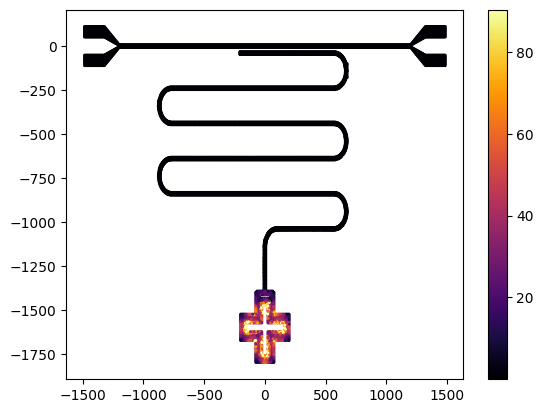

In [21]:
%matplotlib inline
eigenmode_simulation.plot_field(field="E",index=1) # plot magnitude of electric field [V/m]

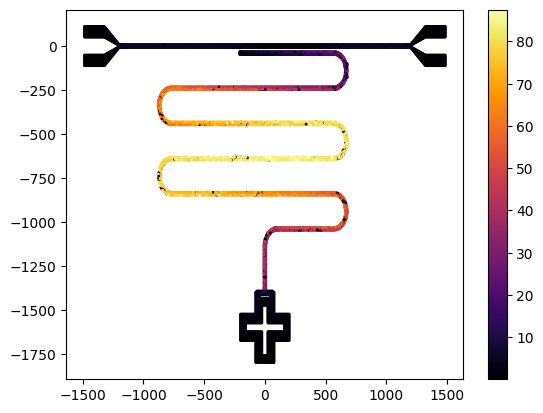

In [22]:
eigenmode_simulation.plot_field(field="E",index=3) # plot magnitude of electric field [V/m]

the above field distributions confirm that the first mode corresponds to our qubit and the third mode corresponds to the resonator. The second mode looks deceivingly like the resonator mode as well but the field shape implies it's a spurious mode. This would probably be removed with the addition of airbridges.

# Extract simulation results 

This eigenmode simulation gives us a plethora of relevant data for superconducting circuits:
* **Resonant frequencies**  $\rightarrow$ intrinsically returned from eigenmode sims.
* **Resonator's $\kappa_\text{tot}$** $\rightarrow$ returned from the complex eigenmode frequency ($\kappa_\text{tot} = \kappa_\text{int} + \kappa_\text{ext}$)
* **Resonator's $\kappa_\text{ext}$** $\rightarrow$ automatically returned if we define external feedline ports.
* **Energy participation of the junction (EPR)** $\rightarrow$ automatically returned if we define a junction lumped port.

pyPalace has some nice functionality to cleanly extract these simulation results. 

In [23]:
# extract simulation results needed for EPR 
## eigenmode frequencies
fq = eigenmode_simulation.get_frequency_eigenmode(mode=1) # qubit frequency [Hz]
fr = eigenmode_simulation.get_frequency_eigenmode(mode=3) # resonator frequency [Hz]

## participation ratios
pq = eigenmode_simulation.get_portEPR(port_index=1,mode=1) # qubit participation
pr = eigenmode_simulation.get_portEPR(port_index=1,mode=3) # resonator participation

## normalize the ratios 
# not always necessary with Palace from my experience but my Mac Silicon Palace install returns unscaled values
pq = pq/(pq+pr)
pr = pr/(pq+pr)

## resonator photon decay rates (kappa_total, kappa_ext, kappa_int)
kappa_tot = eigenmode_simulation.get_kappa_eigenmode(mode=3)
kappa_ext = eigenmode_simulation.get_kappa_ext(mode=3,ports=[2,3])
kappa_int = kappa_tot - kappa_ext

# EPR Analysis

An eigenmode simulation of a transmon-resonator system followed by EPR analysis enables us to extract almost every Hamiltonian parameter of interest. EPR is an especially useful quantum analysis technique since it is geometry agnostic. **But** eigenmode simulations are the most computationally expensive simulation type, especially as one moves to larger devices: solving a large system for many eigenvalues (which give the mode frequencies) and their associated eigenvectors (field distributions) is among the hardest tasks in numerical linear algebra ([Elkin et al., arXiv:2511.20774 (2025)](https://arxiv.org/abs/2511.20774), Secs. II C and IV A).

## Brief look at EPR

Below is a brief look at EPR analysis. Quantum mechanically the participation $p_m$ of the junction in mode $m$ is given by [Minev et al. (2021)](https://doi.org/10.1038/s41534-021-00457-2):

$$
p_m = \frac{\langle\psi_m|\frac{1}{2}E_J\hat{\varphi}^2|\psi_m\rangle}{\langle\psi_m|\frac{1}{2}\hat{H}_\text{lin}|\psi_m\rangle}
$$

where $\hat{H}_\text{lin} = \hbar\omega_r\hat{a}^\dagger\hat{a} + \hbar\omega_q\hat{b}^\dagger\hat{b}$. Palace extracts the participations classically (see [here](https://awslabs.github.io/palace/stable/reference/#Energy-participation-ratios)).

$$
p_{mj} = \frac{L_j I_{mj}^2}{2\mathcal{E}_m^\text{elec}}
$$

where $p_{mj}$ is the participation of junction $j$ in mode $m$, $I_{mj}$ is the is the peak current of junction $j$ for mode $m$,   $\mathcal{E}_m^\text{elec}$ is the electric energy stored in mode $m$.


## Using participations for quantum analysis

After extracting participations of the qubit and the resonator, we can use the following analytic equations to compute Hamiltonian parameters [Minev et al. (2021)](https://doi.org/10.1038/s41534-021-00457-2): 

qubit anharmonicity: $$\alpha = p_q^2\frac{\hbar\omega_q^2}{8E_J}$$

qubit–resonator dispersive shift: $$\chi = p_qp_r\frac{\hbar\omega_q\omega_r}{4E_J}$$

We can use the dispersive shift to calculate the qubit-resonator coupling strength [non-RWA] [Shanto et al. (2024)](https://doi.org/10.22331/q-2024-09-09-1465):


$$
g=\sqrt{\frac{\chi}{2\left(\frac{\alpha_q}{\Delta(\Delta-\alpha_q)}+\frac{\alpha_q}{\Sigma(\Sigma+\alpha_q)}\right)}}
$$


> For a more in-depth look at quantum analysis techniques, check out the **EM Quantum Analysis Techniques** workshop led by Alp Sipahigil (if you are attending QDW).


In [24]:
from pypalace.analysis import EPR

In [25]:
alpha = EPR.calculate_anharmonicity(pq, fq, LJ)
chi = EPR.calculate_dispersive_shift(pq, pr, fq, fr, LJ)
g = EPR.calculate_coupling_strength(fq, fr, alpha, chi)

We now have all the desired Hamiltonian parameters for a single transmon-resonator system:

> $\kappa$ values are particularly sensitive to simulation paramters from my experience. To get reasonable values, we need finer mesh/AMR and better simulation parameters. The values below will probably be much too large since this is a quick simulation demo.

In [28]:
print("Hamiltonian parameters:")
print("=======================")
print("\nQubit parameters:")
print("-----------------------")
print(f"f_q = {fq/1e9:.2f} GHz")
print(f"alpha = {alpha/1e6:.2f} MHz")
print("\nResonator parameters:")
print("-----------------------")
print(f"f_r = {fr/1e9:.2f} GHz")
print(f"kappa_tot = {kappa_tot/1e6:.2f} MHz") 
print(f"kappa_ext = {kappa_ext/1e6:.2f} MHz")
print(f"kappa_int = {kappa_int/1e6:.2f} MHz")
print("\nCoupled parameters:")
print("-----------------------")
print(f"chi = {chi/1e6:.2f} MHz")
print(f"g = {g/1e6:.2f} MHz")

print("\nMesh resolution and simulation parameters were very coarse - these values have large uncertainties")

Hamiltonian parameters:

Qubit parameters:
-----------------------
f_q = 5.37 GHz
alpha = -200.10 MHz

Resonator parameters:
-----------------------
f_r = 6.81 GHz
kappa_tot = 49.84 MHz
kappa_ext = 15.45 MHz
kappa_int = 34.39 MHz

Coupled parameters:
-----------------------
chi = -0.28 MHz
g = 40.19 MHz

Mesh resolution and simulation parameters were very coarse - these values have large uncertainties


<!-- # Next tutorial: electrostatic simulation + LOM

Continue with [`electrostatic_LOM.ipynb`](./electrostatic_LOM.ipynb) — electrostatic simulation of a grounded transmon with capacitance extraction and LOM analysis. -->
